In [50]:
import sys
sys.path.insert(0, './code')

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
%matplotlib widget

# Kalibrace

P =  [[-6.96589521e+01 -4.71026729e+03  1.02032640e+03 -1.12200834e+03]
 [-4.65533017e+03  3.11209418e+01  6.68672290e+02  7.13168161e+02]
 [-6.41830233e-02  2.46744326e-02  9.97633055e-01 -1.14815264e+00]]
K =  [[-4.73406801e+03  3.47132230e+00  9.06159092e+02]
 [-0.00000000e+00 -4.60280096e+03  9.66650635e+02]
 [-0.00000000e+00 -0.00000000e+00  1.00000000e+00]]
R_CB =  [[-0.00316072 -0.99969429  0.02452207]
 [-0.99793314  0.00157934 -0.06424139]
 [ 0.06418302 -0.02467443 -0.99763305]]
t_CB =  [-0.01694621  0.39606984  1.14815264]
RMS Error =  4.947346105260555
--------------------------------------------------
Positions shape: (55, 3)
Errors shape: (55,)


<>:76: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:76: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
C:\Users\ondra\AppData\Local\Temp\ipykernel_49288\861926079.py:76: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  cbar.set_label("Reprojection error $\Delta$ [pixels]", fontsize=12)


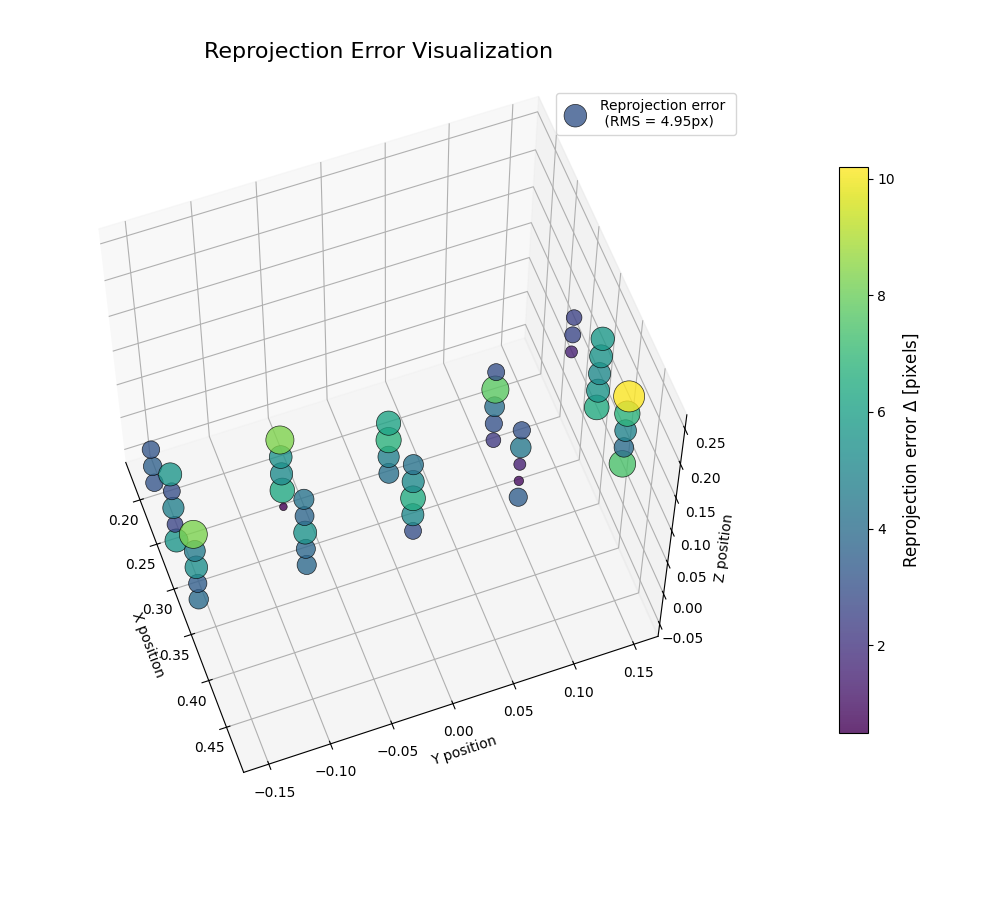

In [51]:
from camera import (
    load_camera_calibration,
    calibrate_camera,
    load_calibration_data,
    METADATA_PATH,
    CALIBRATION_PATH,
)

# Load calibration data
calib_results = load_camera_calibration(path=f"./code/{CALIBRATION_PATH}")

print("P = ", calib_results["P"])
print("K = ", calib_results["K"])
print("R_CB = ", calib_results["R_CB"])
print("t_CB = ", calib_results["t_CB"])
print("RMS Error = ", calib_results["rms_error"])
print("-" * 50)

metadata, images = load_calibration_data(path=f"./code/{METADATA_PATH}")

# Extract 3D positions and reprojection errors
positions = np.array([m["translation_vector"] for m in metadata]).squeeze()

errors = np.asarray(calib_results["reprojection_errors"]).flatten()

print("Positions shape:", positions.shape)
print("Errors shape:", errors.shape)

# Make sure positions have shape (N, 3)
positions = positions.reshape(-1, 3)

# Check that every point has a corresponding error
assert len(positions) == len(errors), (
    f"Number of positions ({len(positions)}) "
    f"does not match number of errors ({len(errors)})"
)

# Normalize reprojection errors for visualization
norm = Normalize(vmin=errors.min(), vmax=errors.max())

# Map errors to colors
cmap = cm.viridis
colors = cmap(norm(errors))

# Map errors to marker sizes
# Adjust these values to change the appearance
min_size = 30
max_size = 500

if errors.max() == errors.min():
    sizes = np.full(len(errors), (min_size + max_size) / 2)
else:
    sizes = min_size + ((errors - errors.min()) / (errors.max() - errors.min())) * (
        max_size - min_size
    )

# Create interactive 3D plot
fig = plt.figure(figsize=(10, 9))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    positions[:, 0],
    positions[:, 1],
    positions[:, 2],
    c=errors,
    cmap=cmap,
    norm=norm,
    s=sizes,
    alpha=0.8,
    edgecolors="black",
    linewidths=0.5,
)

# Add colorbar
cbar = fig.colorbar(scatter, ax=ax, shrink=0.65, pad=0.1)
cbar.set_label("Reprojection error $\Delta$ [pixels]", fontsize=12)

# Axis labels
ax.set_xlabel("X position")
ax.set_ylabel("Y position")
ax.set_zlabel("Z position")

ax.set_title("Reprojection Error Visualization", fontsize=16, pad=20)

# Make the 3D axes have equal scale
ranges = np.ptp(positions, axis=0)
max_range = max(ranges.max(), 1e-6)

midpoints = (positions.max(axis=0) + positions.min(axis=0)) / 2

ax.set_xlim(midpoints[0] - max_range / 2, midpoints[0] + max_range / 2)
ax.set_ylim(midpoints[1] - max_range / 2, midpoints[1] + max_range / 2)
ax.set_zlim(midpoints[2] - max_range / 2, midpoints[2] + max_range / 2)

ax.set_box_aspect((0.85, 1, 1))

ax.view_init(
    elev=60,  # Elevation angle in degrees
    azim=-20,  # Azimuth angle in degrees
    roll=0,  # Rotation around the viewing axis (Matplotlib 3.6+)
)

plt.tight_layout()
plt.legend(
    handles=[scatter],
    labels=["Reprojection error \n (RMS = 4.95px)"],
    loc="upper right",
)
plt.show()

# Export as SVG
fig.savefig(
    "report_visualization_exports/3d_reprojection_errors.svg",
    format="svg",
    bbox_inches="tight",
    pad_inches=0.15,
    transparent=False,
)